## Figure 3
Uncertainty Decomposition: 100 samples, 51 ensemble members, hotonly mortality rates

### Initialization

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "utils").is_dir()
)
sys.path.insert(0, str(PROJECT_ROOT))

import os
from datetime import datetime, UTC
from dotenv import find_dotenv, load_dotenv
import xarray as xr
import xvec

import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.ticker import MultipleLocator
import cartopy.crs as ccrs

from utils import analysis_utils
from utils import isku_utils
from utils import plotting_utils
from utils import stats_utils

import importlib

importlib.reload(analysis_utils)
importlib.reload(isku_utils)
importlib.reload(plotting_utils)

/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<module 'utils.plotting_utils' from '/home/emily_zuetell/projects/poreallas/utils/plotting_utils.py'>

In [2]:
load_dotenv(
    find_dotenv("october_local.env", raise_error_if_not_found=True), override=True
)

EFFECTS_URI = os.environ["POREALLAS_EFFECTS_URI"]
IMPACT_REGION_POLYGONS = os.environ["POREALLAS_REGIONS_POLYGONS_URI"]
SOCIOECONOMICS_URI = os.environ["POREALLAS_SOCIOECONOMICS_URI"]

### Function Defs 

In [3]:
def plot_variance_decomposition(da, x_dim, factors=("sample", "number"),
                                labels=None, colors=None, figsize=(6.5, 5),
                                x_order=None):
    a, b = factors
    labels = labels or [a.capitalize(), b.capitalize(), "Interaction"]
    colors = colors or ["#0072B2", "#E69F00", "#6E706F"]  # Okabe-Ito, colorblind-safe
    # Month Order
    if x_order is not None:
        da = da.sel({x_dim: list(x_order)})

    # Two-way decomposition (ddof=0 makes it exact: total = var_a + var_b + var_ab)
    grand = da.mean((a, b))
    mean_a = da.mean(b)                      # varies along a
    mean_b = da.mean(a)                      # varies along b
    resid = da - mean_a - mean_b + grand
    # Decomposed Variance
    comps = [mean_a.var(a), mean_b.var(b), (resid ** 2).mean((a, b))]
    total = da.var((a, b))
    # Set x order
    x_vals = da[x_dim].values
    x = list(range(len(x_vals)))
    ys = [c.transpose(x_dim).values for c in comps]
    shares = [100 * y / total.values for y in ys]

    fig, (ax1, ax2) = plt.subplots(
        2, 1, sharex=True, figsize=figsize, constrained_layout=True,
        gridspec_kw={"height_ratios": [1.4, 1]},
    )
    # Raw Variance #
    ax1.stackplot(x, ys, labels=labels, colors=colors, alpha=0.9, linewidth=0)
    ax1.plot(x, total.values, color="k", lw=1.2, label="Total")
    ax1.set_ylabel("Variance")
    ax1.set_ylim(bottom=0)
    ax1.legend(ncol=4, frameon=False, loc="lower left",
               bbox_to_anchor=(0, 1.02), fontsize=9)
    ## Variance Share ##
    ax2.stackplot(x, shares, colors=colors, alpha=0.9, linewidth=0)
    ax2.set_ylim(0, 100)
    ax2.set_ylabel("Share of variance (%)")
    ax2.set_xlabel(x_dim)
    ax2.set_xlim(x[0], x[-1])
    ax2.set_xticks(x, [str(v) for v in x_vals])

    for ax, tag in zip((ax1, ax2), ("(a)", "(b)")):
        ax.spines[["top", "right"]].set_visible(False)
        ax.tick_params(direction="out", labelsize=9)
        ax.text(-0.1, 1.1, tag, transform=ax.transAxes,
                fontsize=11, fontweight="bold", va="top")

    return fig, (ax1, ax2)

### Figure Plotting

In [4]:
# Baseline period for Impact
effect = xr.open_datatree(EFFECTS_URI, consolidated=False)
BASELINE_PERIOD = analysis_utils.get_baseline_period(effect, years=30)
# Define Forecast Months
FC_MONTHS = [10, 11, 12, 1, 2, 3]
FC_PERIOD = slice("2026-10-01", "2027-03-31")

config = analysis_utils.ImpactConfig(version = f"v{datetime.now(tz=UTC):%y%m%d}",
                                     baseline_period=BASELINE_PERIOD, 
                                     polygons_path= os.environ["POREALLAS_REGIONS_POLYGONS_URI"],
                                     socioeconomics_path= os.environ["POREALLAS_SOCIOECONOMICS_URI"],
                                     rate=True, 
                                     months = FC_MONTHS,
                                     hotonly = "hotonly", 
                                     dims = ['number', 'sample'])

In [5]:
effect_path = EFFECTS_URI
effect = xr.open_datatree(effect_path)
# Compute impact: forecast - baseline
impact = analysis_utils.compute_impact(
    effect.chunk({dim: -1 for dim in config.dims}),
    config,
    ensemble=True,
)
# Use only the defined 6-months
impact = impact.sel(month=config.months).compute()

# Compute global impact (weighted sum)
global_impact = analysis_utils.compute_global_impact(
            impact, config.socioeconomics, rate=config.rate, group_dim='region'
        ).compute()

/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


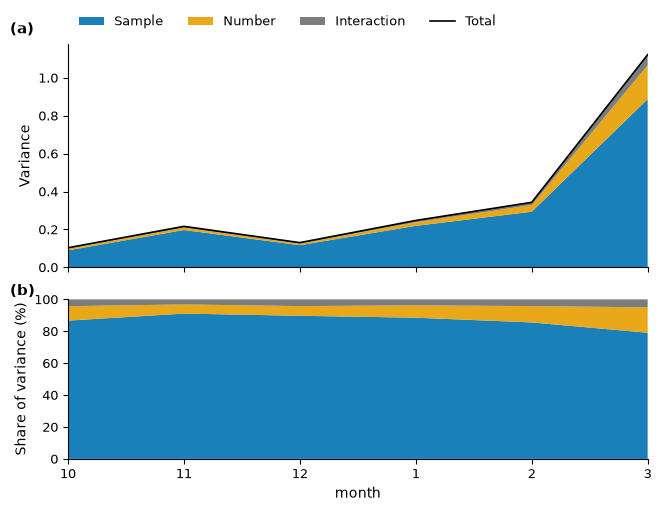

In [6]:
fig, axes = plot_variance_decomposition(global_impact, x_dim="month", x_order=config.months)

In [7]:
fig.savefig(f"{config.version}_fig03_uncertaintydecomp.png", dpi=600, bbox_inches="tight")